# Tugas Visualisasi Data: Transformasi Data Menjadi Informasi & Informasi Strategis (Zona USD & EUR)
**Berdasarkan Hasil Co-Creation Data Retail Global (`global_retail_prices_dataset.csv`)**

---
## Kerangka Piramida DIKW (*Data - Information - Knowledge/Strategic Information*)
Dalam manajemen sistem informasi dan analitika bisnis, pengolahan data dibagi menjadi tiga lapisan utama yang dipisahkan dengan jelas di dalam Notebook ini:

| Lapisan Analitik | Tahapan dalam Notebook | Pertanyaan yang Dijawab | Output Utama |
| :--- | :--- | :--- | :--- |
| **1. FASE PRA-PEMROSESAN DATA (*Data Preparation*)** | **Tahap 1:** Pembersihan Data (*Data Cleaning*) | *"Apakah data mentah sudah valid, bersih dari duplikat, dan siap diolah?"* | Dataset bersih (**1.639 baris**) bebas *missing values* tanpa identitas & bebas duplikat. |
| **2. FASE INFORMASI (*Descriptive Information*)** | **Tahap 2, 3, 4, & 5:** Evaluasi *Imbalance*, Profil Supermarket, Harga Pasaran (*Market Price*), & Klasifikasi Frekuensi Barang | *"Apa yang sedang terjadi di pasar? Berapa harga pasaran di tiap zona dan bagaimana proporsi barang harian vs bulanan?"* | Fakta terukur & visualisasi deskriptif (EUR **50,34%** & USD **24,71%**; Median pasar USD **$9,49** & EUR **€2,45**). |
| **3. FASE INFORMASI STRATEGIS (*Strategic & Prescriptive Information*)** | **Tahap 6, 7, & 8:** Pemetaan Posisi Kompetitor Termurah, *Target Price Anchor*, & Skenario Strategi Penetapan Harga | *"Keputusan bisnis apa yang harus diambil? Berapa harga yang harus dipasang jika membuka supermarket baru & bagaimana strategi promonya?"* | Matriks *Positioning* Kompetitor, Patokan Harga Toko Baru, serta **Strategi Bisnis Skenario 1 (EDLP + Promo Gajian)** & **Skenario 2 (Pantry Anchor + Flash Sale)**. |

**Referensi Akademik Konsep Informasi vs Informasi Strategis (DIKW Hierarchy):**
* Rowley, J. (2007). *The wisdom hierarchy: representations of the DIKW hierarchy*. Journal of Information Science: [https://journals.sagepub.com/doi/10.1177/0165551506070706](https://journals.sagepub.com/doi/10.1177/0165551506070706)
* Gartner Glossary — *Descriptive vs. Diagnostic vs. Predictive vs. Prescriptive Analytics*: [https://www.gartner.com/en/information-technology/glossary/advanced-analytics](https://www.gartner.com/en/information-technology/glossary/advanced-analytics)

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 50)
sns.set_theme(style='whitegrid', palette='muted')

# 0. Memuat Dataset Mentah (Raw Data)
df_raw = pd.read_csv('../global_retail_prices_dataset.csv')
print(f'Ukuran Data Mentah (Raw Data): {df_raw.shape[0]} baris x {df_raw.shape[1]} kolom')
display(df_raw.head())

print('\n Kualitas Data Mentah:')
missing_summary = pd.DataFrame({
    'Missing Count': df_raw.isnull().sum(),
    'Missing Percentage (%)': (df_raw.isnull().sum() / len(df_raw) * 100).round(2),
    'Unique Values': df_raw.nunique(dropna=False)
})
display(missing_summary)

Ukuran Data Mentah (Raw Data): 2000 baris x 12 kolom


,price_record_id,product_code,product_name,brand,category,price,currency,price_is_discounted,store_name,city,country_code,date_recorded
0,339639,NaN,APFEL ROT LOSE,NaN,en:apples,2.08,EUR,False,jbieber,Hofer,NaN,2026-10-03
1,339638,4061461467661,Orient. Salat 200g,NaN,NaN,1.29,EUR,False,jbieber,Hofer,NaN,2026-10-03
2,339637,NaN,Toskanabrot 360g,NaN,en:white-breads,1.80,EUR,False,jbieber,Hofer,NaN,2026-10-03
3,339636,4061464512245,Waffelhörn. Erdb.,NaN,NaN,0.49,EUR,False,jbieber,Hofer,NaN,2026-10-03
4,339635,4061458026819,Orient. Salat 200g,NaN,NaN,1.29,EUR,False,jbieber,Hofer,NaN,2026-10-03



 Kualitas Data Mentah:


,Missing Count,Missing Percentage (%),Unique Values
price_record_id,0,0.00,2000
product_code,134,6.70,1762
product_name,461,23.05,1517
brand,2000,100.00,1
category,1866,93.30,65
price,0,0.00,608
currency,0,0.00,20
price_is_discounted,0,0.00,1
store_name,0,0.00,63
city,0,0.00,79


---
# BAGIAN I: FASE PRA-PEMROSESAN DATA (*DATA PREPARATION PHASE*)
> **Tujuan Fase Ini:** Mengubah *Raw Data* (2.000 baris yang masih kotor dan belum terstruktur) menjadi *Clean Data* (1.639 baris valid) agar visualisasi **Informasi** dan **Informasi Strategis** pada tahap berikutnya tidak terdistorsi oleh *noise* atau duplikasi.

## Tahap 1. Pembersihan Data (*Data Cleaning*) & Tautan Sumber Metodologi

Berikut adalah **5 kondisi ketidaksempurnaan data** beserta penanganan dan tautan sumber metodologinya:

### Kondisi 1.1: Kolom 100% Kosong (`brand`, `country_code`) & Kolom *Zero-Variance* (`price_is_discounted`)
* **Masalah:** Kolom `brand` dan `country_code` memiliki 2.000 nilai `NaN` (100% kosong). Kolom `price_is_discounted` bernilai `False` pada seluruh 2.000 baris (variansi = 0), sehingga ketiganya tidak memberikan informasi pembeda (*zero information gain*).
* **Penanganan:** Menghapus ketiga kolom tersebut menggunakan `.drop(columns=[...])`.
* **Sumber Referensi:**
  * [Pandas Documentation — Working with Missing Data (`dropna`)](https://pandas.pydata.org/docs/user_guide/missing_data.html)
  * [Scikit-Learn Documentation — Feature Selection: Removing Features with Low/Zero Variance](https://scikit-learn.org/stable/modules/feature_selection.html#removing-features-with-low-variance)

### Kondisi 1.2: Pergeseran Label Kolom (*Schema Misalignment*) & Standardisasi Nama Supermarket
* **Masalah:** Kolom `store_name` berisi *username* kontributor (seperti `poslovitch`, `doby`), sedangkan nama supermarket sesungguhnya tercatat di kolom `city` (seperti `Dumbo Market`, `E. Leclerc`). Selain itu terdapat perbedaan penulisan huruf besar/kecil atau cabang untuk jaringan ritel yang sama (`REWE` vs `Rewe`, `E.Leclerc Levallois` vs `E. Leclerc`).
* **Penanganan:** Mengubah nama kolom `city` menjadi `supermarket_name` dan `store_name` menjadi `contributor_id`, serta melakukan normalisasi teks.
* **Sumber Referensi:**
  * [Pandas Documentation — Working with Text Data & String Normalization](https://pandas.pydata.org/docs/user_guide/text.html)
  * [Data Carpentry — Data Cleaning & Text Clustering Best Practices](https://datacarpentry.org/OpenRefine-ecology-lesson/01-working-with-openrefine/index.html)

### Kondisi 1.3: *Missing Values* Parsial pada `product_name` (461 Baris Kosong)
* **Masalah:** Terdapat 461 baris tanpa `product_name`.
* **Penanganan Berjenjang (*Hierarchical Imputation & Listwise Deletion*):**
  1. **Imputasi via Barcode (`product_code`):** Memulihkan **11 baris** yang memiliki barcode identik dengan baris bernama lengkap.
  2. **Imputasi via Kategori (`category`):** Memulihkan **115 baris** dengan mengambil nama kategori (menghapus awalan `en:`, contoh `en:yogurts` -> `Yogurts`).
  3. **Eliminasi Baris Tanpa Identitas (*Listwise Deletion*):** Menghapus **335 baris** yang sama sekali tidak memiliki `product_name` maupun `category`.
* **Sumber Referensi:**
  * [Stef van Buuren — Flexible Imputation of Missing Data (Chapter 1: Deductive Imputation & Listwise Deletion)](https://stefvanbuuren.name/fimd/sec-simplesolutions.html)
  * [Pandas Documentation — Filling Missing Values (`fillna` & `map`)](https://pandas.pydata.org/docs/reference/api/pandas.Series.fillna.html)

### Kondisi 1.4: Duplikasi Pencatatan Transaksi Identik (*Exact Duplicate Records*)
* **Masalah:** Terdapat **26 baris duplikat** dengan kombinasi (`product_code`, `product_name`, `price`, `currency`, `supermarket_name`, `date_recorded`) yang sama persis.
* **Penanganan:** Menghapus duplikat menggunakan `.drop_duplicates()` sehingga menghasilkan **1.639 baris data bersih**.
* **Sumber Referensi:**
  * [Pandas Documentation — Duplicate Labels (`drop_duplicates`)](https://pandas.pydata.org/docs/user_guide/duplicates.html)

=== AUDIT PEMBERSIHAN DATA (DATA PREPARATION) ===
1. Data Mentah Awal                         : 2000 baris
2. Dipulihkan via Barcode & Kategori        : 126 baris (11 barcode + 115 kategori)
3. Dihapus karena Tanpa Identitas Produk    : -335 baris
4. Dihapus karena Duplikasi Transaksi       : -26 baris
5. Total Data Bersih Siap Visualisasi       : 1639 baris


C:\Users\zazki\AppData\Local\Temp\ipykernel_20416\2719502658.py:55: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x=stages, y=counts, palette=['#95a5a6', '#f39c12', '#27ae60'])


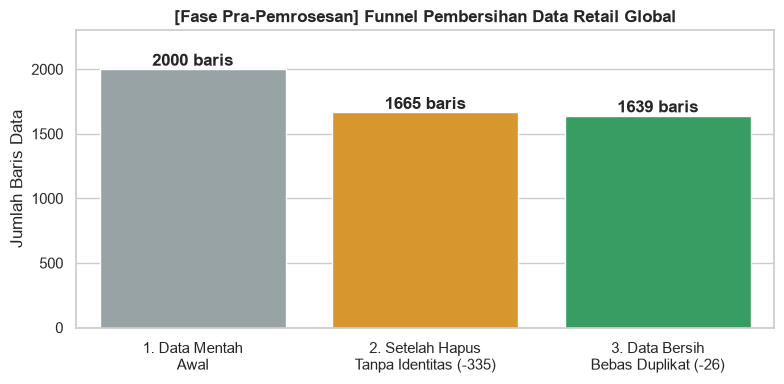

In [9]:
# Eksekusi Tahap 1: Data Cleaning + Visualisasi Funnel Pembersihan Data
df_clean = df_raw.drop(columns=['brand', 'country_code', 'price_is_discounted']).copy()

df_clean = df_clean.rename(columns={'city': 'supermarket_name', 'store_name': 'contributor_id'})
df_clean['supermarket_name'] = df_clean['supermarket_name'].str.strip().replace({
    'REWE': 'Rewe',
    'E.Leclerc Levallois': 'E. Leclerc',
    'Intermarché Super': 'Intermarché',
    'U Express Lyon Université': 'U Express'
})

initial_missing_name = df_clean['product_name'].isnull().sum()

# Imputasi dari product_code
code_to_name = (
    df_clean.dropna(subset=['product_code', 'product_name'])
    .groupby('product_code')['product_name']
    .first()
    .to_dict()
)
df_clean['product_name'] = df_clean['product_name'].fillna(df_clean['product_code'].map(code_to_name))
after_barcode_missing = df_clean['product_name'].isnull().sum()

# Imputasi dari category
df_clean['category_clean'] = (
    df_clean['category']
    .str.replace('en:', '', regex=False)
    .str.replace('-', ' ', regex=False)
    .str.title()
)
df_clean['product_name'] = df_clean['product_name'].fillna(df_clean['category_clean'])
after_category_missing = df_clean['product_name'].isnull().sum()

# Hapus baris tanpa identitas produk
df_clean = df_clean.dropna(subset=['product_name']).copy()
rows_after_dropna = len(df_clean)

# Hapus duplikat transaksi
df_clean = df_clean.drop_duplicates(
    subset=['product_code', 'product_name', 'price', 'currency', 'supermarket_name', 'date_recorded']
).copy()
rows_final_clean = len(df_clean)

print('=== AUDIT PEMBERSIHAN DATA (DATA PREPARATION) ===')
print(f'1. Data Mentah Awal                         : {len(df_raw)} baris')
print(f'2. Dipulihkan via Barcode & Kategori        : {(initial_missing_name - after_barcode_missing) + (after_barcode_missing - after_category_missing)} baris (11 barcode + 115 kategori)')
print(f'3. Dihapus karena Tanpa Identitas Produk    : -{after_category_missing} baris')
print(f'4. Dihapus karena Duplikasi Transaksi       : -{rows_after_dropna - rows_final_clean} baris')
print(f'5. Total Data Bersih Siap Visualisasi       : {rows_final_clean} baris')

# Visualisasi Alur Pembersihan Data
stages = ['1. Data Mentah\nAwal', '2. Setelah Hapus\nTanpa Identitas (-335)', '3. Data Bersih\nBebas Duplikat (-26)']
counts = [len(df_raw), rows_after_dropna, rows_final_clean]
plt.figure(figsize=(8, 4))
ax = sns.barplot(x=stages, y=counts, palette=['#95a5a6', '#f39c12', '#27ae60'])
plt.title('[Fase Pra-Pemrosesan] Funnel Pembersihan Data Retail Global', fontweight='bold')
plt.ylabel('Jumlah Baris Data')
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())} baris', (p.get_x() + p.get_width()/2., p.get_height()),
                ha='center', va='bottom', fontweight='bold')
plt.ylim(0, 2300)
plt.tight_layout()
plt.show()

---
# BAGIAN II: FASE INFORMASI (*DESCRIPTIVE INFORMATION PHASE*)
> **Apa itu Fase Informasi?**
> Fase **Informasi** menjawab pertanyaan **"Apa yang terjadi di dalam data?" (*What is happening?*)**. Pada fase ini, data bersih diolah melalui agregasi, pengelompokan, dan visualisasi statistik deskriptif untuk mengungkap fakta objektif tentang kondisi pasar, distribusi mata uang, profil toko, harga pasaran wajar (*market price*), serta komposisi barang yang sering vs jarang dibeli. **Fase ini mencakup Tahap 2, Tahap 3, Tahap 4, dan Tahap 5.**

---
## Tahap 2 [FASE INFORMASI]: Informasi Ketimpangan Data (*Imbalanced Data*) & Fokus ke Zona USD dan EUR

### Informasi yang Didapat dari Visualisasi Distribusi Mata Uang:
* Dari **1.639 data bersih**, distribusi transaksi sangat timpang (*imbalanced*): zona **EUR memiliki 825 produk (50,34%)** dan zona **USD memiliki 405 produk (24,71%)**. Artinya, **75,05% populasi data terkonsentrasi hanya pada 2 mata uang ini**, sedangkan 7 mata uang lainnya (NOK, BAM, CZK, KZT, SGD, PLN, THB) hanya menyumbang 24,95% sisanya (bahkan KZT, SGD, PLN, dan THB masing-masing di bawah 20 baris).

### Landasan Ilmiah: Apakah Boleh Memfokuskan Analisis Hanya pada Beberapa Data Mayoritas (USD & EUR) Saat Data *Imbalanced*?
**Sangat boleh dan secara metodologi statistika justru direkomendasikan**, karena:
1. **Mencegah *Small Sample Bias* & *High Variance Estimator*:** Mengambil kesimpulan harga pasaran dari mata uang yang hanya memiliki 1 hingga 17 sampel (seperti THB = 1, PLN = 13, SGD = 16, KZT = 17) akan menghasilkan *standard error* yang sangat besar ($SE = \frac{s}{\sqrt{n}}$) dan informasi yang menyesatkan.
2. **Prinsip *Subpopulation / Domain Analysis*:** Memfokuskan ruang lingkup analisis pada sub-populasi utama yang memenuhi kecukupan ukuran sampel (*minimum sample size threshold*) menjaga validitas kesimpulan bisnis.

**Sumber Literatur Terkait Penanganan *Imbalanced Data* & *Subpopulation Filtering*:**
* [NIST/SEMATECH e-Handbook of Statistical Methods — Exploratory Data Analysis & Sample Size](https://www.itl.nist.gov/div898/handbook/eda/section1/eda11.htm)
* [Google Developers Machine Learning Crash Course — Imbalanced Datasets & Distribution Bias](https://developers.google.com/machine-learning/crash-course/overfitting/imbalanced-datasets)
* [PennState STAT 504 — Stratified Analysis & Sparse Data Filtering](https://online.stat.psu.edu/stat504/)

,Currency,Clean Row Count,Share (%),Cumulative Share (%),Kategori Sampel
0,EUR,825,50.34,50.34,Fokus Analisis Utama (75.05% Data)
1,USD,405,24.71,75.05,Fokus Analisis Utama (75.05% Data)
2,NOK,181,11.04,86.09,Dieliminasi (Sampel Minoritas)
3,BAM,110,6.71,92.80,Dieliminasi (Sampel Minoritas)
4,CZK,71,4.33,97.13,Dieliminasi (Sampel Minoritas)
5,KZT,17,1.04,98.17,Dieliminasi (Sampel Minoritas)
6,SGD,16,0.98,99.15,Dieliminasi (Sampel Minoritas)
7,PLN,13,0.79,99.94,Dieliminasi (Sampel Minoritas)
8,THB,1,0.06,100.00,Dieliminasi (Sampel Minoritas)


C:\Users\zazki\AppData\Local\Temp\ipykernel_20416\4116496137.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(data=curr_table, x='Currency', y='Clean Row Count', palette=colors)


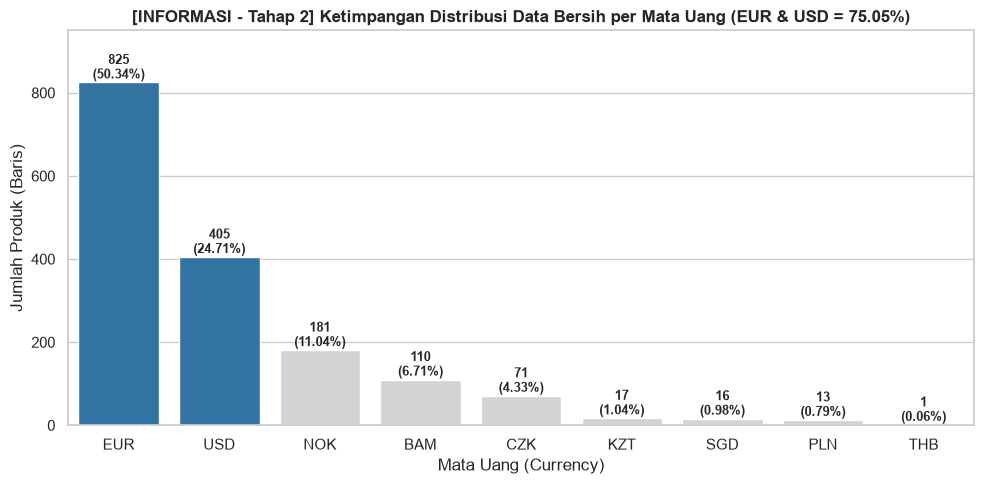

In [10]:
# Visualisasi Tahap 2 [FASE INFORMASI]: Ketimpangan Distribusi Mata Uang (Imbalanced Data)
curr_table = df_clean['currency'].value_counts().reset_index()
curr_table.columns = ['Currency', 'Clean Row Count']
curr_table['Share (%)'] = (curr_table['Clean Row Count'] / len(df_clean) * 100).round(2)
curr_table['Cumulative Share (%)'] = curr_table['Share (%)'].cumsum().round(2)
curr_table['Kategori Sampel'] = np.where(
    curr_table['Currency'].isin(['EUR', 'USD']),
    'Fokus Analisis Utama (75.05% Data)',
    'Dieliminasi (Sampel Minoritas)'
)
display(curr_table)

plt.figure(figsize=(10, 5))
colors = ['#1f77b4' if c in ['EUR', 'USD'] else '#d3d3d3' for c in curr_table['Currency']]
ax = sns.barplot(data=curr_table, x='Currency', y='Clean Row Count', palette=colors)
plt.title('[INFORMASI - Tahap 2] Ketimpangan Distribusi Data Bersih per Mata Uang (EUR & USD = 75.05%)', fontsize=12, fontweight='bold')
plt.xlabel('Mata Uang (Currency)')
plt.ylabel('Jumlah Produk (Baris)')
for p, pct in zip(ax.patches, curr_table['Share (%)']):
    ax.annotate(f'{int(p.get_height())}\n({pct}%)', (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='bottom', fontsize=9, fontweight='bold')
plt.ylim(0, 950)
plt.tight_layout()
plt.show()

# Memisahkan dataset fokus: USD dan EUR
df_usd = df_clean[df_clean['currency'] == 'USD'].copy()
df_eur = df_clean[df_clean['currency'] == 'EUR'].copy()

---
## Tahap 3 & 4 [FASE INFORMASI]: Informasi Profil Supermarket & Harga Pasaran (*Market Price*) di Zona USD dan EUR

### Informasi Deskriptif yang Didapat dari Tahap 3 & 4:
1. **Informasi Harga Pasaran Zona USD ($):**
   * Dari **405 produk** di 6 jaringan supermarket AS, **harga pasaran wajar (Median / $Q_2$) adalah $9,49** dengan rata-rata (*Mean*) **$10,91** dan rentang kuartil wajar ($Q_1 - Q_3$) di **$5,99 hingga $14,99**.
   * **Informasi Keragaman Toko USD:** Sampel USD didominasi oleh **Dumbo Market (288 produk)** yang menjual produk *gourmet*/impor (minyak zaitun, saus pasta, es krim artisanal) dengan median **$9,99**, serta **Whole Foods Market (67 produk)** yang berfokus pada produk organik dan madu Manuka premium dengan median **$12,49**. Sementara itu, jaringan supermarket harian seperti **Smart & Final extra! (20 produk)**, **Safeway (15 produk)**, dan **ShopRite (11 produk)** memiliki median harga jauh lebih rendah (**$3,99 – $4,99**).
2. **Informasi Harga Pasaran Zona EUR (€):**
   * Dari **825 produk** di Eropa, **harga pasaran wajar (Median / $Q_2$) adalah €2,45** dengan rata-rata (*Mean*) **€3,12** dan rentang kuartil wajar ($Q_1 - Q_3$) di **€1,78 hingga €3,59**.
   * **Informasi Keragaman Toko EUR:** Pasar Eropa terbagi menjadi tiga segmen jelas: (a) *Hard-Discounter* seperti **Penny, Hofer, dan Norma** (median **€1,27 – €1,99**), (b) *Hypermarket / Supermarket Efisien* seperti **E. Leclerc (213 produk, median €2,05)**, **Colruyt (151 produk, median €2,25)**, **Carrefour Market (202 produk, median €2,65)**, dan **Intermarché (84 produk, median €2,72)**, serta (c) *Urban Premium Store* seperti **Monoprix (69 produk, median €3,99)**.

=== [INFORMASI] RINGKASAN HARGA PASARAN ZONA USD vs EUR ===


,Zona Mata Uang,Jumlah Produk,Jumlah Supermarket,Mean Price,Median Price (Harga Pasaran Wajar),Q1 (25% Pasar Bawah),Q3 (75% Pasar Atas),Min Price,Max Price
0,USD ($),405,6,10.91,9.49,5.99,14.99,0.50,43.99
1,EUR (€),825,14,3.12,2.45,1.78,3.59,0.23,25.87



=== [INFORMASI] PROFIL SUPERMARKET & BARANG DI ZONA USD ($) ===


,jumlah_produk,mean_price,median_price,q1_price,q3_price,contoh_barang
supermarket_name,,,,,,
Dumbo Market,288,10.99,9.74,6.49,14.99,"MINA LEMONS PRESERVED 12.5 OZ PK 6, LUCIEN APR..."
Whole Foods Market,67,14.52,11.84,9.56,18.49,"OG RED CABBAGE, TAZA OG CHOCO PURO DISC, 365WF..."
Smart & Final extra!,20,4.44,3.99,3.99,3.99,"Talenti Tahitian Vanilla Bean 16 oz, Ben & Jer..."
Safeway,15,5.28,4.99,3.99,6.49,"KOZY SHACK PUDDING TAPIOCA 22 OZ, REYNALDO'S R..."
ShopRite,11,5.46,2.99,1.49,5.34,"BC CHALLAH BREAD, Pillsbury Funfetti Unicorn V..."
Walmart Supercenter,4,12.73,13.13,6.31,19.55,"BATH SCALE, HONEYCOMB, MONSTER LED"



=== [INFORMASI] PROFIL TOP 12 SUPERMARKET & BARANG DI ZONA EUR (€) ===


,jumlah_produk,mean_price,median_price,q1_price,q3_price,contoh_barang
supermarket_name,,,,,,
E. Leclerc,213,2.64,2.04,1.65,2.98,"BIO VILL FLAN NAPPE 4X125G, SOJASUN MYRTILLES ..."
Carrefour Market,202,3.58,2.67,1.99,3.85,"OY LT2X100G LOT N, BOUTEILLE PET 75CL, BREIZH ..."
Colruyt,151,3.08,2.28,1.66,3.28,"GALLO H.OLIVE EXTRA VIERG 40 2.000 L, HENAFF P..."
Intermarché,84,3.48,2.72,2.07,3.70,"PAVE D AFFINOIS 200G, TOFU NATURE BIO X2 CEREA..."
Monoprix,69,4.16,3.99,3.39,4.55,"DUO DE POISSONS RIZ CUISINE, HA CO.CHILI SIN C..."
Carrefour City,52,2.52,2.28,2.01,3.10,"4X100G POMME ABRICOT AND, 200G BOULETTE DE BLE..."
Hofer,18,1.26,1.37,0.61,1.76,"APFEL ROT LOSE, Orient. Salat 200g, Toskanabro..."
Penny,10,1.11,1.27,0.60,1.38,"KAFFEEGEBAECK, SAHNEP. VANILLE, GRANDUETT SCHOKO"
Norma,8,1.74,1.99,1.46,2.12,"Macadamiakerne geröstet, Frz. Butter-Croissant..."


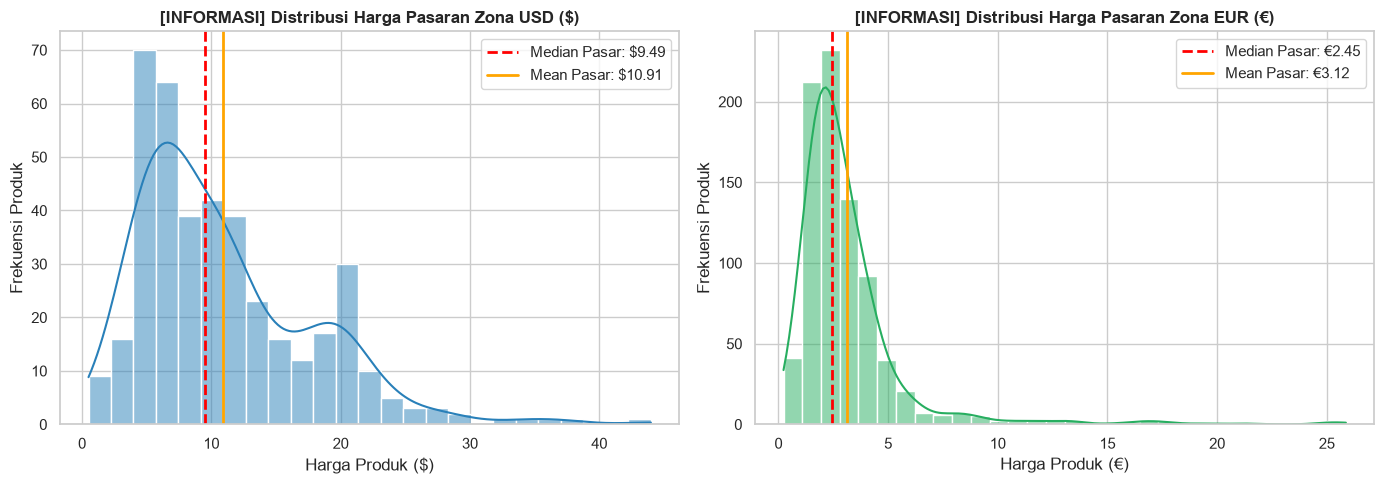

In [11]:
# Tabel & Visualisasi Tahap 3 & 4 [FASE INFORMASI]: Harga Pasaran & Distribusi per Supermarket
market_overview = pd.DataFrame({
    'Zona Mata Uang': ['USD ($)', 'EUR (€)'],
    'Jumlah Produk': [len(df_usd), len(df_eur)],
    'Jumlah Supermarket': [df_usd['supermarket_name'].nunique(), df_eur['supermarket_name'].nunique()],
    'Mean Price': [df_usd['price'].mean().round(2), df_eur['price'].mean().round(2)],
    'Median Price (Harga Pasaran Wajar)': [df_usd['price'].median().round(2), df_eur['price'].median().round(2)],
    'Q1 (25% Pasar Bawah)': [df_usd['price'].quantile(0.25).round(2), df_eur['price'].quantile(0.25).round(2)],
    'Q3 (75% Pasar Atas)': [df_usd['price'].quantile(0.75).round(2), df_eur['price'].quantile(0.75).round(2)],
    'Min Price': [df_usd['price'].min().round(2), df_eur['price'].min().round(2)],
    'Max Price': [df_usd['price'].max().round(2), df_eur['price'].max().round(2)]
})
print('=== [INFORMASI] RINGKASAN HARGA PASARAN ZONA USD vs EUR ===')
display(market_overview)

# Tabel Profil Supermarket USD & EUR
usd_store_info = df_usd.groupby('supermarket_name').agg(
    jumlah_produk=('price', 'count'),
    mean_price=('price', lambda x: round(x.mean(), 2)),
    median_price=('price', lambda x: round(x.median(), 2)),
    q1_price=('price', lambda x: round(x.quantile(0.25), 2)),
    q3_price=('price', lambda x: round(x.quantile(0.75), 2)),
    contoh_barang=('product_name', lambda x: ', '.join(x.head(3)))
).sort_values(by='jumlah_produk', ascending=False)
print('\n=== [INFORMASI] PROFIL SUPERMARKET & BARANG DI ZONA USD ($) ===')
display(usd_store_info)

eur_store_info = df_eur.groupby('supermarket_name').agg(
    jumlah_produk=('price', 'count'),
    mean_price=('price', lambda x: round(x.mean(), 2)),
    median_price=('price', lambda x: round(x.median(), 2)),
    q1_price=('price', lambda x: round(x.quantile(0.25), 2)),
    q3_price=('price', lambda x: round(x.quantile(0.75), 2)),
    contoh_barang=('product_name', lambda x: ', '.join(x.head(3)))
).sort_values(by='jumlah_produk', ascending=False)
print('\n=== [INFORMASI] PROFIL TOP 12 SUPERMARKET & BARANG DI ZONA EUR (€) ===')
display(eur_store_info.head(12))

# Visualisasi Boxplot & Histogram Distribusi Harga Pasaran USD vs EUR
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(df_usd['price'], bins=25, kde=True, color='#2980b9', ax=axes[0])
axes[0].axvline(df_usd['price'].median(), color='red', linestyle='--', linewidth=2, label=f"Median Pasar: ${df_usd['price'].median():.2f}")
axes[0].axvline(df_usd['price'].mean(), color='orange', linestyle='-', linewidth=2, label=f"Mean Pasar: ${df_usd['price'].mean():.2f}")
axes[0].set_title('[INFORMASI] Distribusi Harga Pasaran Zona USD ($)', fontweight='bold')
axes[0].set_xlabel('Harga Produk ($)')
axes[0].set_ylabel('Frekuensi Produk')
axes[0].legend()

sns.histplot(df_eur['price'], bins=30, kde=True, color='#27ae60', ax=axes[1])
axes[1].axvline(df_eur['price'].median(), color='red', linestyle='--', linewidth=2, label=f"Median Pasar: €{df_eur['price'].median():.2f}")
axes[1].axvline(df_eur['price'].mean(), color='orange', linestyle='-', linewidth=2, label=f"Mean Pasar: €{df_eur['price'].mean():.2f}")
axes[1].set_title('[INFORMASI] Distribusi Harga Pasaran Zona EUR (€)', fontweight='bold')
axes[1].set_xlabel('Harga Produk (€)')
axes[1].set_ylabel('Frekuensi Produk')
axes[1].legend()

plt.tight_layout()
plt.show()

---
## Tahap 5 [FASE INFORMASI]: Informasi Pembagian Kategori Barang Berdasarkan Frekuensi Pembelian (Sering vs Jarang Dibeli)

Pada tahap terakhir di **Fase Informasi** ini, kita mengelompokkan produk menjadi:
1. **Barang Harian/Mingguan (Sering Dibeli / *Fast-Moving Consumer Goods*):** Roti, susu, yogurt, keju, buah/sayur segar, daging/sosis/nabati siap masak, makanan siap saji, es krim *pint*, camilan, dan minuman ringan.
2. **Barang Bulanan/Tahunan (Jarang Dibeli / *Slow-Moving Pantry & Stock Items*):** Minyak zaitun/minyak goreng, madu, sirup *maple*, bumbu dapur/garam/lada, saus botol/mayones, selai/Nutella, kaldu kemasan, kopi biji 1 kg/kapsul, teh celup, popok bayi (*Pampers*), minuman beralkohol botol besar (*Champagne/Liqueur*), serta perlengkapan rumah tangga.

### Informasi Deskriptif yang Didapat dari Tahap 5:
* **Di Zona USD ($):** Komposisi produk terbagi hampir seimbang antara **Barang Jarang Dibeli (209 produk / 51,6%)** dengan harga pasaran median **$10,49** (mean **$12,17**) dan **Barang Sering Dibeli (196 produk / 48,4%)** dengan harga pasaran median **$6,99** (mean **$9,56**).
* **Di Zona EUR (€):** Mayoritas pencatatan transaksi merupakan **Barang Sering Dibeli (660 produk / 80,0%)** dengan median **€2,48** (mean **€2,93**), sedangkan **Barang Jarang Dibeli mencakup 165 produk (20,0%)** dengan median **€2,38** namun rata-rata (*mean*) lebih tinggi yaitu **€3,88** karena adanya item stok ukuran besar (seperti popok bayi dan minyak zaitun 2 liter).

=== [INFORMASI] STATISTIK HARGA PER KATEGORI FREKUENSI DI ZONA USD ($) ===


,count,mean,median,min,max,std
freq_category,,,,,,
Bulanan/Tahunan (Jarang Dibeli),211,12.2,10.49,1.39,43.99,7.16
Harian/Mingguan (Sering Dibeli),194,9.5,6.99,0.50,26.99,5.97



=== [INFORMASI] STATISTIK HARGA PER KATEGORI FREKUENSI DI ZONA EUR (€) ===


,count,mean,median,min,max,std
freq_category,,,,,,
Bulanan/Tahunan (Jarang Dibeli),172,3.88,2.44,0.69,25.87,4.58
Harian/Mingguan (Sering Dibeli),653,2.92,2.47,0.23,15.49,1.83


C:\Users\zazki\AppData\Local\Temp\ipykernel_20416\3925283229.py:37: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_usd, x='freq_category', y='price', palette=['#e67e22', '#3498db'], ax=axes[0])
C:\Users\zazki\AppData\Local\Temp\ipykernel_20416\3925283229.py:42: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_eur, x='freq_category', y='price', palette=['#2ecc71', '#9b59b6'], ax=axes[1])


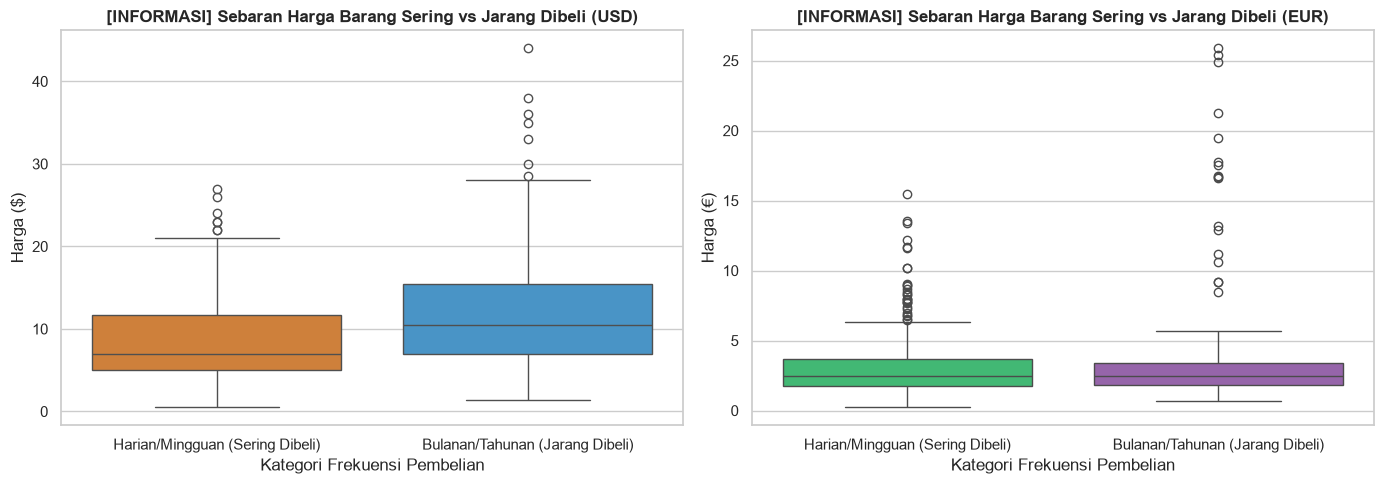

In [12]:
# Klasifikasi & Visualisasi Tahap 5 [FASE INFORMASI]: Barang Sering Dibeli vs Jarang Dibeli
rare_keywords = [
    'OIL', 'HUILE', 'OLIVE', 'EVOO', 'TRUFFL', 'TRFL', 'VINEGAR', 'VINAIGRE',
    'HONEY', 'HNY', 'MIEL', 'MANUKA', 'SYRUP', 'SIROP', 'MAPLE', 'MOLASSES', 'AGAVE',
    'SALT', 'SEL ', 'PEPPER', 'POIVRE', 'SPICE', 'SEASONING', 'SSNG', 'GARLIC PWDR', 'POWDER',
    'CINNAMON', 'CUMIN', 'PAPRIKA', 'OREGANO', 'TURMERIC', 'CURRY', 'HERB', 'VANILLA BEAN',
    'EXTRACT', 'FLOUR', 'FARINE', 'SUGAR', 'SUCRE', 'BAKING', 'CAKE MIX', 'FROSTING', 'YEAST', 'LEVURE',
    'SAUCE', 'SCE', 'MAYONNAISE', 'MAYO', 'MUSTARD', 'MOUTARDE', 'KETCHUP', 'PESTO', 'ALFREDO',
    'MARINARA', 'SALSA', 'HOT SAUCE', 'SOY SAUCE', 'TAMARI', 'TERIYAKI', 'NUOC MAM', 'BBQ',
    'JAM', 'JELLY', 'CONFITURE', 'PRESERVE', 'MARMALADE', 'SPREAD', 'NUTELLA', 'NUTELA',
    'PEANUT BUTTER', 'CASHEW BUTTER', 'ALMOND BUTTER', 'TAHINI', 'PATE DE SESAME',
    'BROTH', 'STOCK', 'BOUILLON', 'CANNED', 'CONSERVE', 'BOCAL', 'PICKLE', 'CORNICHON', 'CAPERS', 'OLIVES',
    'COUCHES', 'PAMPERS', 'BABYDRY', 'BABY DRY', 'DIAPER', 'BATH SCALE', 'MONSTER LED',
    'CHAMPAGNE', 'LIQUEUR', 'JAGERMEISTER', 'WHISKY', 'VODKA', 'GIN ', 'RUM ', 'RHUM', 'PICON', 'GET 31', 'VIN ', 'WINE',
    '1KG GRAINS', 'COFFEE BEANS', 'GROUND COFFEE', 'STARBUCK', 'CAPS', 'CAPSULES', 'NESCAF', 'CAFE',
    'TEA ', 'INFUS', 'TISANE', 'TALLOW', 'GHEE', 'LARD'
]

def classify_purchase_frequency(row):
    combined_text = f"{str(row['product_name']).upper()} {str(row['category']).upper()}"
    for kw in rare_keywords:
        if kw in combined_text:
            return 'Bulanan/Tahunan (Jarang Dibeli)'
    return 'Harian/Mingguan (Sering Dibeli)'

df_usd['freq_category'] = df_usd.apply(classify_purchase_frequency, axis=1)
df_eur['freq_category'] = df_eur.apply(classify_purchase_frequency, axis=1)

print('=== [INFORMASI] STATISTIK HARGA PER KATEGORI FREKUENSI DI ZONA USD ($) ===')
display(df_usd.groupby('freq_category')['price'].agg(['count', 'mean', 'median', 'min', 'max', 'std']).round(2))

print('\n=== [INFORMASI] STATISTIK HARGA PER KATEGORI FREKUENSI DI ZONA EUR (€) ===')
display(df_eur.groupby('freq_category')['price'].agg(['count', 'mean', 'median', 'min', 'max', 'std']).round(2))

# Visualisasi Proporsi & Perbandingan Harga Barang Sering vs Jarang Dibeli
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(data=df_usd, x='freq_category', y='price', palette=['#e67e22', '#3498db'], ax=axes[0])
axes[0].set_title('[INFORMASI] Sebaran Harga Barang Sering vs Jarang Dibeli (USD)', fontweight='bold')
axes[0].set_xlabel('Kategori Frekuensi Pembelian')
axes[0].set_ylabel('Harga ($)')

sns.boxplot(data=df_eur, x='freq_category', y='price', palette=['#2ecc71', '#9b59b6'], ax=axes[1])
axes[1].set_title('[INFORMASI] Sebaran Harga Barang Sering vs Jarang Dibeli (EUR)', fontweight='bold')
axes[1].set_xlabel('Kategori Frekuensi Pembelian')
axes[1].set_ylabel('Harga (€)')

plt.tight_layout()
plt.show()

---
# BAGIAN III: FASE INFORMASI STRATEGIS (*STRATEGIC & PRESCRIPTIVE INFORMATION PHASE*)
> **Apa itu Fase Informasi Strategis?**
> Berbeda dengan Fase Informasi yang hanya mendeskripsikan fakta masa lalu/saat ini (*What is happening?*), **Fase Informasi Strategis** menjawab pertanyaan **"Di mana celah pasar kita, berapa harga yang harus kita tetapkan, dan strategi bisnis apa yang harus dieksekusi?" (*So What & Now What?*)**. Informasi strategis menghubungkan hasil komparasi harga kompetitor langsung ke pengambilan keputusan manajerial (pembukaan supermarket baru, *price positioning*, dan *promotional calendar*). **Fase ini mencakup Tahap 6, Tahap 7, dan Tahap 8.**

---
## Tahap 6 [FASE MENUJU INFORMASI STRATEGIS]: Pemetaan Kompetitor Termurah untuk Barang Sering vs Jarang Dibeli

Mengapa perbandingan harga antar supermarket pada kategori barang sering vs jarang dibeli ini termasuk ke dalam **Informasi Strategis**?
Karena dari tabel silang (*cross-tabulation*) dan kuadran *positioning* di bawah ini, manajemen dapat mengidentifikasi **siapa kompetitor langsung (*head-to-head benchmark*)** yang harus dikalahkan harganya jika kita memilih fokus bisnis tertentu:

### Informasi Strategis Peta Kompetitor Zona USD ($):
* **Kompetitor Termurah di Barang Harian/Mingguan (Sering Dibeli):** **Smart & Final extra!** (Mean **$4,12** | Median **$3,99**) dan **ShopRite** (Median **$3,99** | Mean **$6,34**), disusul **Safeway** (Mean **$5,44** | Median **$4,99**). Mereka adalah *benchmark* efisiensi harga harian.
* **Kompetitor di Segmen *Gourmet & Organic* (Mahal di Kedua Kategori):** **Dumbo Market** (Mean Harian **$10,81** | Mean Bulanan **$11,15**) dan **Whole Foods Market** (Mean Harian **$9,81** | Mean Bulanan **$16,67**). Ini membuka **celah pasar strategis (*market gap*)** yang besar di rentang harga menengah **$5,50 – $9,50**.

### Informasi Strategis Peta Kompetitor Zona EUR (€):
* **Kompetitor Termurah Kategori *Hard-Discounter* (Khusus Harian):** **Penny** (Mean **€1,11** | Median **€1,27**) dan **Hofer** (Mean **€1,26** | Median **€1,37**).
* **Kompetitor Termurah Kategori *Full-Service Hypermarket* (Sering & Jarang Dibeli):** **E. Leclerc** memimpin efisiensi di kedua lini sekaligus (Mean Harian **€2,61** / Median **€2,04**; Mean Bulanan **€2,77** / Median **€2,13**), diikuti ketat oleh **Colruyt** (Median Harian **€2,19**; Median Bulanan **€2,37**).
* **Anomali Strategis pada Monoprix (Inspirasi Strategi Skenario 2):** **Monoprix** mematok harga barang harian/siap saji tinggi (Mean **€4,31** | Median **€4,14**), tetapi mematok barang stok bulanan lebih murah (Mean **€3,33** | Median **€3,39**).

=== [INFORMASI] KOMPARASI KOMPETITOR ZONA USD ($) ===


count  \
freq_category        Bulanan/Tahunan (Jarang Dibeli)   
supermarket_name                                       
Dumbo Market                                     153   
Safeway                                            2   
ShopRite                                           2   
Smart & Final extra!                               5   
Walmart Supercenter                                3   
Whole Foods Market                                46   

                                                      \
freq_category        Harian/Mingguan (Sering Dibeli)   
supermarket_name                                       
Dumbo Market                                     135   
Safeway                                           13   
ShopRite                                           9   
Smart & Final extra!                              15   
Walmart Supercenter                                1   
Whole Foods Market                                21   

                                                mean  \
freq_category        Bulanan/Tahunan (Jarang Dibeli)   
supermarket_name                                       
Dumbo Market                                   11.26   
Safeway                                         4.19   
ShopRite                                        1.49   
Smart & Final extra!                            5.41   
Walmart Supercenter                            15.38   
Whole Foods Market                             16.67   

                                                      \
freq_category        Harian/Mingguan (Sering Dibeli)   
supermarket_name                                       
Dumbo Market                                   10.68   
Safeway                                         5.44   
ShopRite                                        6.34   
Smart & Final extra!                            4.12   
Walmart Supercenter                             4.78   
Whole Foods Market                              9.81   

                                              median  \
freq_category        Bulanan/Tahunan (Jarang Dibeli)   
supermarket_name                                       
Dumbo Market                                    9.99   
Safeway                                         4.19   
ShopRite                                        1.49   
Smart & Final extra!                            5.99   
Walmart Supercenter                            19.44   
Whole Foods Market                             12.64   

                                                      
freq_category        Harian/Mingguan (Sering Dibeli)  
supermarket_name                                      
Dumbo Market                                    7.99  
Safeway                                         4.99  
ShopRite                                        3.99  
Smart & Final extra!                            3.99  
Walmart Supercenter                             4.78  
Whole Foods Market                              6.69


=== [INFORMASI] KOMPARASI KOMPETITOR UTAMA ZONA EUR (€) ===


count  \
freq_category    Bulanan/Tahunan (Jarang Dibeli)   
supermarket_name                                   
Carrefour City                               6.0   
Carrefour Market                            64.0   
Colruyt                                     36.0   
E. Leclerc                                  41.0   
Hofer                                        NaN   
Intermarché                                 11.0   
Monoprix                                    11.0   
Norma                                        NaN   
Penny                                        NaN   

                                                  \
freq_category    Harian/Mingguan (Sering Dibeli)   
supermarket_name                                   
Carrefour City                              46.0   
Carrefour Market                           138.0   
Colruyt                                    115.0   
E. Leclerc                                 172.0   
Hofer                                       18.0   
Intermarché                                 73.0   
Monoprix                                    58.0   
Norma                                        8.0   
Penny                                       10.0   

                                            mean  \
freq_category    Bulanan/Tahunan (Jarang Dibeli)   
supermarket_name                                   
Carrefour City                              3.02   
Carrefour Market                            3.83   
Colruyt                                     4.57   
E. Leclerc                                  2.77   
Hofer                                        NaN   
Intermarché                                 7.22   
Monoprix                                    3.33   
Norma                                        NaN   
Penny                                        NaN   

                                                  \
freq_category    Harian/Mingguan (Sering Dibeli)   
supermarket_name                                   
Carrefour City                              2.45   
Carrefour Market                            3.47   
Colruyt                                     2.62   
E. Leclerc                                  2.61   
Hofer                                       1.26   
Intermarché                                 2.91   
Monoprix                                    4.31   
Norma                                       1.74   
Penny                                       1.11   

                                          median  \
freq_category    Bulanan/Tahunan (Jarang Dibeli)   
supermarket_name                                   
Carrefour City                              3.05   
Carrefour Market                            2.29   
Colruyt                                     2.42   
E. Leclerc                                  2.13   
Hofer                                        NaN   
Intermarché                                 2.72   
Monoprix                                    3.39   
Norma                                        NaN   
Penny                                        NaN   

                                                  
freq_category    Harian/Mingguan (Sering Dibeli)  
supermarket_name                                  
Carrefour City                              2.20  
Carrefour Market                            2.80  
Colruyt                                     2.18  
E. Leclerc                                  2.04  
Hofer                                       1.37  
Intermarché                                 2.72  
Monoprix                                    4.14  
Norma                                       1.99  
Penny                                       1.27

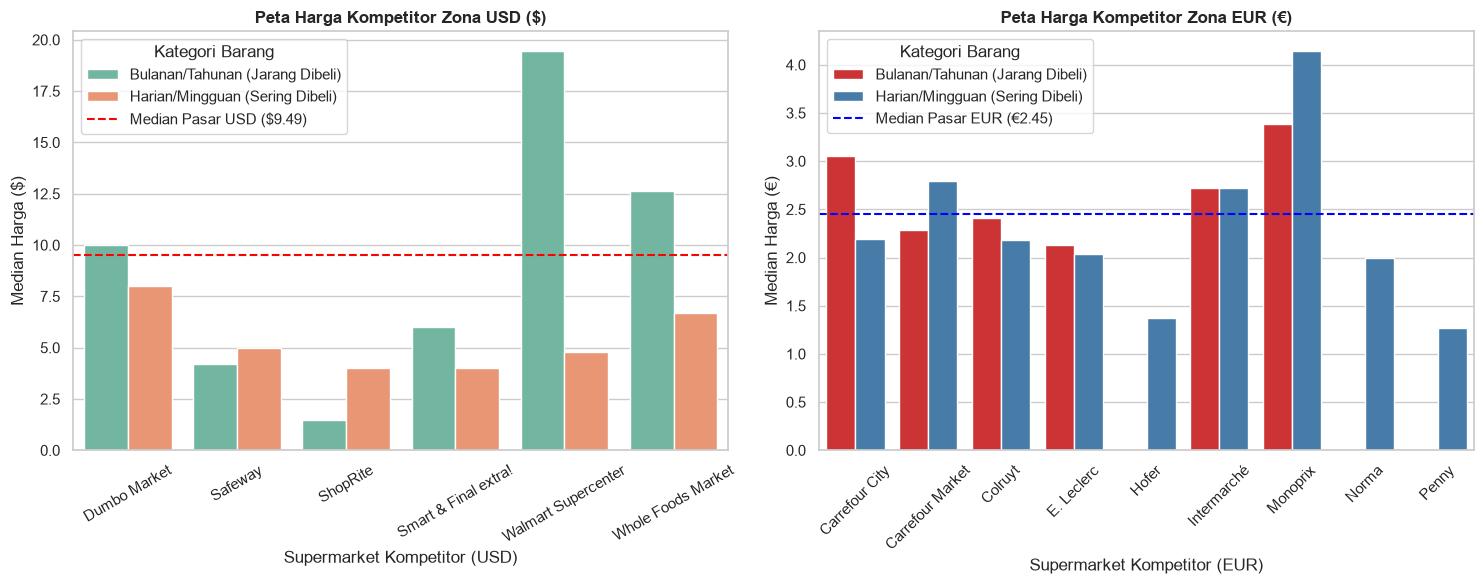

In [13]:
# Tabel & Visualisasi Tahap 6 [FASE INFORMASI STRATEGIS]: Komparasi Harga Kompetitor & Kuadran Positioning
usd_comp = df_usd.pivot_table(
    index='supermarket_name',
    columns='freq_category',
    values='price',
    aggfunc=['count', 'mean', 'median']
).round(2)
print('=== [INFORMASI] KOMPARASI KOMPETITOR ZONA USD ($) ===')
display(usd_comp)

top_eur_stores = df_eur['supermarket_name'].value_counts()[lambda x: x >= 8].index
eur_comp = df_eur[df_eur['supermarket_name'].isin(top_eur_stores)].pivot_table(
    index='supermarket_name',
    columns='freq_category',
    values='price',
    aggfunc=['count', 'mean', 'median']
).round(2)
print('\n=== [INFORMASI] KOMPARASI KOMPETITOR UTAMA ZONA EUR (€) ===')
display(eur_comp)

# Visualisasi Bar Chart Komparasi Harga Median Kompetitor
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
usd_plot_df = df_usd.groupby(['supermarket_name', 'freq_category'])['price'].median().reset_index()
sns.barplot(data=usd_plot_df, x='supermarket_name', y='price', hue='freq_category', palette='Set2', ax=axes[0])
axes[0].axhline(df_usd['price'].median(), color='red', linestyle='--', label='Median Pasar USD ($9.49)')
axes[0].set_title('Peta Harga Kompetitor Zona USD ($)', fontweight='bold')
axes[0].set_xlabel('Supermarket Kompetitor (USD)')
axes[0].set_ylabel('Median Harga ($)')
axes[0].tick_params(axis='x', rotation=30)
axes[0].legend(title='Kategori Barang')

eur_plot_df = df_eur[df_eur['supermarket_name'].isin(top_eur_stores)].groupby(['supermarket_name', 'freq_category'])['price'].median().reset_index()
sns.barplot(data=eur_plot_df, x='supermarket_name', y='price', hue='freq_category', palette='Set1', ax=axes[1])
axes[1].axhline(df_eur['price'].median(), color='blue', linestyle='--', label='Median Pasar EUR (€2.45)')
axes[1].set_title('Peta Harga Kompetitor Zona EUR (€)', fontweight='bold')
axes[1].set_xlabel('Supermarket Kompetitor (EUR)')
axes[1].set_ylabel('Median Harga (€)')
axes[1].tick_params(axis='x', rotation=45)
axes[1].legend(title='Kategori Barang')

plt.tight_layout()
plt.show()

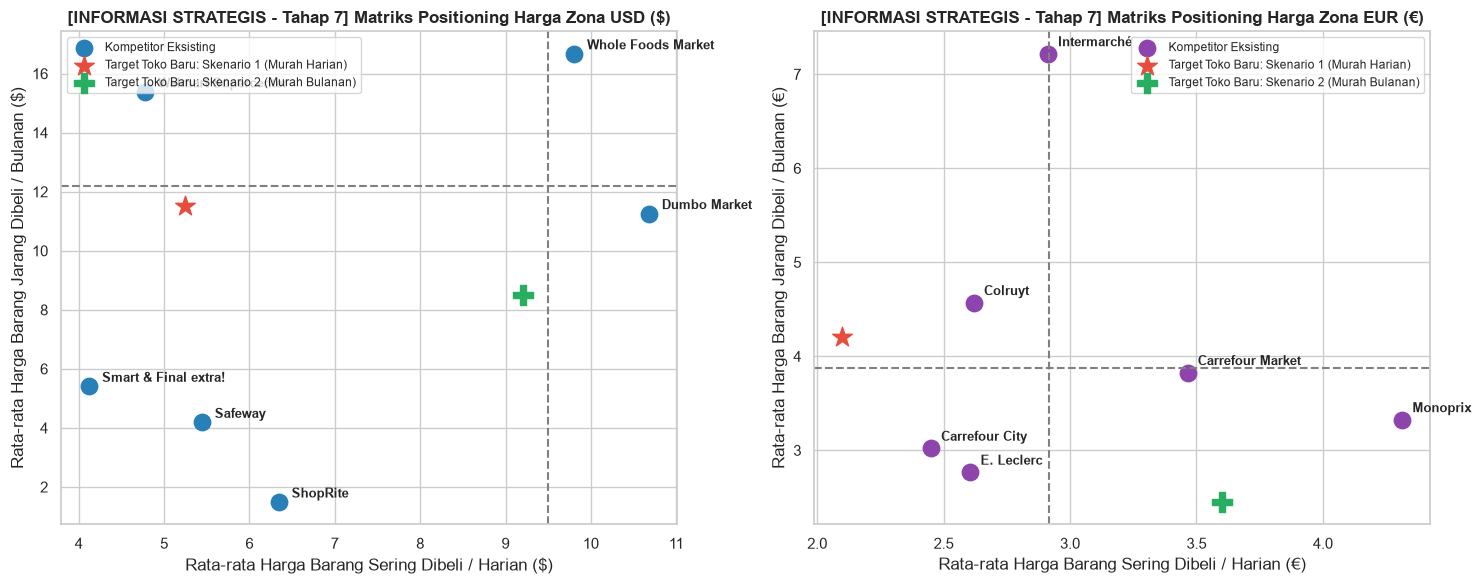

In [14]:
# Visualisasi Matriks Kuadran Positioning Strategis (Scatter Plot 2D: Harga Harian vs Harga Bulanan + Target Toko Baru)
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Data Kuadran USD
usd_quad = df_usd.pivot_table(index='supermarket_name', columns='freq_category', values='price', aggfunc='mean').dropna()
axes[0].scatter(usd_quad['Harian/Mingguan (Sering Dibeli)'], usd_quad['Bulanan/Tahunan (Jarang Dibeli)'], s=140, color='#2980b9', label='Kompetitor Eksisting')
for store, row in usd_quad.iterrows():
    axes[0].annotate(store, (row['Harian/Mingguan (Sering Dibeli)'] + 0.15, row['Bulanan/Tahunan (Jarang Dibeli)'] + 0.15), fontsize=9, fontweight='bold')
# Titik Target Supermarket Baru kita di USD (Skenario 1 & Skenario 2)
axes[0].scatter([5.25], [11.50], s=220, color='#e74c3c', marker='*', label='Target Toko Baru: Skenario 1 (Murah Harian)')
axes[0].scatter([9.20], [8.50], s=220, color='#27ae60', marker='P', label='Target Toko Baru: Skenario 2 (Murah Bulanan)')
axes[0].axvline(df_usd[df_usd['freq_category']=='Harian/Mingguan (Sering Dibeli)']['price'].mean(), color='gray', linestyle='--')
axes[0].axhline(df_usd[df_usd['freq_category']=='Bulanan/Tahunan (Jarang Dibeli)']['price'].mean(), color='gray', linestyle='--')
axes[0].set_title('[INFORMASI STRATEGIS - Tahap 7] Matriks Positioning Harga Zona USD ($)', fontweight='bold')
axes[0].set_xlabel('Rata-rata Harga Barang Sering Dibeli / Harian ($)')
axes[0].set_ylabel('Rata-rata Harga Barang Jarang Dibeli / Bulanan ($)')
axes[0].legend(loc='upper left', fontsize=8.5)

# Data Kuadran EUR
eur_quad = df_eur[df_eur['supermarket_name'].isin(top_eur_stores)].pivot_table(index='supermarket_name', columns='freq_category', values='price', aggfunc='mean').dropna()
axes[1].scatter(eur_quad['Harian/Mingguan (Sering Dibeli)'], eur_quad['Bulanan/Tahunan (Jarang Dibeli)'], s=140, color='#8e44ad', label='Kompetitor Eksisting')
for store, row in eur_quad.iterrows():
    axes[1].annotate(store, (row['Harian/Mingguan (Sering Dibeli)'] + 0.04, row['Bulanan/Tahunan (Jarang Dibeli)'] + 0.08), fontsize=9, fontweight='bold')
# Titik Target Supermarket Baru kita di EUR (Skenario 1 & Skenario 2)
axes[1].scatter([2.10], [4.20], s=220, color='#e74c3c', marker='*', label='Target Toko Baru: Skenario 1 (Murah Harian)')
axes[1].scatter([3.60], [2.45], s=220, color='#27ae60', marker='P', label='Target Toko Baru: Skenario 2 (Murah Bulanan)')
axes[1].axvline(df_eur[df_eur['freq_category']=='Harian/Mingguan (Sering Dibeli)']['price'].mean(), color='gray', linestyle='--')
axes[1].axhline(df_eur[df_eur['freq_category']=='Bulanan/Tahunan (Jarang Dibeli)']['price'].mean(), color='gray', linestyle='--')
axes[1].set_title('[INFORMASI STRATEGIS - Tahap 7] Matriks Positioning Harga Zona EUR (€)', fontweight='bold')
axes[1].set_xlabel('Rata-rata Harga Barang Sering Dibeli / Harian (€)')
axes[1].set_ylabel('Rata-rata Harga Barang Jarang Dibeli / Bulanan (€)')
axes[1].legend(loc='upper right', fontsize=8.5)

plt.tight_layout()
plt.show()

---
## Tahap 7 & 8 [FASE INFORMASI STRATEGIS]: Patokan Harga Supermarket Baru & Eksekusi Strategi Bisnis (*Actionable Business Strategy*)

Berdasarkan sintesis seluruh **Informasi** (Tahap 2–5) dan **Pemetaan Kompetitor** (Tahap 6), berikut adalah **Informasi Strategis & Keputusan Bisnis** jika kita membuka supermarket baru di zona USD maupun EUR:

### 1. Patokan Harga Strategis (*Strategic Price Benchmarking*) untuk Toko Baru

| Zona Pasar | Kategori Barang | Harga Pasaran Saat Ini (Median / Mean) | Kompetitor Termurah Saat Ini | Target Harga Skenario 1 (Condong Murah di Barang Harian) | Target Harga Skenario 2 (Condong Murah di Barang Bulanan) |
| :--- | :--- | :--- | :--- | :--- | :--- |
| **Zona USD ($)** | **Harian / Mingguan (Sering Dibeli)** | **$6,99** / $9,56 | Smart & Final ($3,99) & ShopRite ($3,99) | **$4,25 – $5,49** (*Traffic Builder*) | **$8,50 – $9,50** (*Margin Generator*) |
| **Zona USD ($)** | **Bulanan / Tahunan (Jarang Dibeli)** | **$10,49** / $12,17 | Smart & Final ($6,04) & Dumbo Market ($9,99) | **$10,99 – $12,49** (Diskon saat *Payday* ke ~$8,99) | **$7,99 – $8,99** (*Pantry Anchor*) |
| **Zona EUR (€)** | **Harian / Mingguan (Sering Dibeli)** | **€2,48** / €2,93 | Penny (€1,27), Hofer (€1,37), E. Leclerc (€2,04) | **€1,95 – €2,15** (*Traffic Builder*) | **€3,40 – €3,80** (*Margin Generator*) |
| **Zona EUR (€)** | **Bulanan / Tahunan (Jarang Dibeli)** | **€2,38** / €3,88 | E. Leclerc (€2,13) & Carrefour Market (€2,29) | **€3,80 – €4,50** (Diskon saat *Payday* ke ~€2,99) | **€2,10 – €2,45** (*Pantry Anchor*) |

---
### 2. Rincian Strategi Bisnis Skenario 1 vs Skenario 2

#### Skenario Strategis 1: Condong Murah ke Barang yang Sering Dibeli (*EDLP on Daily Essentials + Hi-Lo Promotional Event on Monthly Stock*)
* **Logika Strategis:** Konsumen sangat hafal harga barang yang mereka beli setiap hari/minggu (seperti susu, roti, telur, buah, dan air mineral). Dengan mematok harga barang harian di bawah median pasar (**$4,25–$5,49** di AS atau **€1,95–€2,15** di Eropa), supermarket kita langsung dipersepsikan murah dan memenangkan *foot traffic* mingguan.
* **Cara Mengamankan Margin & Menjual Barang Jarang Dibeli (Bulanan/Tahunan):**
  1. **Event Diskon Gajian (*Payday Big Pack Promo* — Tanggal 25 s.d. 5 Awal Bulan):** Pada hari biasa, barang bulanan (minyak zaitun, madu, kopi 1 kg, popok bayi, bumbu dapur) dijual dengan harga normal bermargin tinggi. Namun setiap awal bulan saat pelanggan menerima gaji, adakan diskon 20%–25% atau *Buy 2 Save 30%* sehingga pelanggan menunda belanja bulanan di tempat lain dan memborongnya di toko kita pada awal bulan.
  2. **Event Spesial Musiman (*Festive & Seasonal Pantry Fair*):** Mengadakan promo tematik menjelang hari raya atau liburan (misalnya *Baking & Grill Week* untuk saus BBQ, tepung, sirup maple, dan minyak goreng).
  3. **Tebus Murah Berbasis Keranjang Harian (*Basket Threshold Unlock*):** Setiap pembelanjaan barang harian minimal **$35 (USD)** atau **€25 (EUR)**, pelanggan berhak menebus 1 barang stok bulanan (seperti minyak zaitun atau kopi) dengan potongan harga khusus 30%.

#### Skenario Strategis 2 (Pengaturan Sebaliknya): Condong Murah ke Barang yang Jarang Dibeli (*Wholesale Pantry Anchor + Value-Added Convenience on Daily Goods*)
* **Logika Strategis:** Meniru kesuksesan model harga **Monoprix** di data EUR (di mana rata-rata harga barang bulanan **€3,33** lebih murah dibanding barang harian **€4,31**) atau konsep *modern urban pantry*. Kita mengunci pengeluaran terbesar rumah tangga di awal bulan dengan menjual stok bulanan (kopi, minyak zaitun, popok, bumbu, makanan kaleng) pada harga mendekati grosir.
* **Ide Strategi Bisnis agar Barang Harian (yang Harganya Lebih Tinggi) Tetap Laris Terjual:**
  1. **Diferensiasi *Ready-to-Eat & Meal Bundling* (Paket Makan Harian Praktis):** Jangan menjual barang harian sebagai komoditas biasa, melainkan kemas sebagai solusi praktis (*convenience*). Contoh: * Paket Sarapan/Makan Siang Cepat* (Roti Artisan/Croissant + Salad/Sandwich + Minuman Dingin/Yogurt) seharga paket hemat yang tetap memberikan margin bersih tinggi.
  2. **Strategi *Evening Flash Sale / Dynamic Markdown* (Diskon Jam Malam Pukul 19.00–21.00):** Karena barang harian dipasang dengan harga dasar lebih tinggi dan bersifat cepat rusak (*perishable*), terapkan diskon otomatis 35%–50% mulai pukul 19.00 malam. Ini menarik segmen mahasiswa dan pekerja pulang kantor, menjaga *zero food waste*, sekaligus mempertahankan citra kualitas premium di siang hari.
  3. **Program *Pantry Club Cashback* (Siklus Retensi Silang):** Setiap pelanggan berbelanja stok bulanan murah di awal bulan, berikan poin *cashback* atau voucher yang **hanya dapat digunakan untuk membeli produk segar harian** di minggu ke-2 dan ke-3 bulan tersebut. Dengan demikian, pelanggan yang awalnya datang hanya untuk belanja bulanan murah akan terdorong kembali untuk belanja harian.